# Image model (EfficientNetB0) with all-slice evaluation using hybrid gallbladder masks


**Pipeline**
1. Cohort and the patient-level 7:3 train/test split
2. Training of EfficientNetB0 on one representative CT slice per patient
3. Evaluation on the representative slice of each test patient
4. Cropping of **all** gallbladder slices of each test patient (hybrid masks)
5. Slice-level prediction, aggregation to the patient level (a patient is positive if any slice has a predicted probability ≥ 0.5)
6. Performance metrics with 95% confidence intervals

**What is executed in this notebook**
- Training (step 2) and cropping (step 4) are **not re-run** by default (`RUN_TRAINING = False`, `RUN_CROPPING = False`).
  The trained model file and the cropped images produced by the original run are loaded instead.
  GPU training is not bit-for-bit deterministic, so re-training would give a slightly different model.
- Everything else (inference, aggregation, metrics, confidence intervals, figures) is executed here.
  Re-running inference reproduces the slice-level probabilities of the original run (checked below).

**Cohort**: 197 patients (100 with acute cholecystitis, 97 controls). Controls No. 87, 95 and 97 are not part of the study cohort;
No. 95 has no images, and No. 87 and 97 are excluded from the evaluation (`EXCLUDE_PATIENT_IDS`).

**Data availability**: the CT images, masks and clinical data are not included in the repository. Set `root` to the data directory.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import glob
import logging
import cv2
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from IPython.display import Image as IPImage, display
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping, ModelCheckpoint
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, f1_score, ConfusionMatrixDisplay

tf.get_logger().setLevel(logging.ERROR)

# ===== Settings =====
root = "/Users/nomura/work/Dr_horaguchi"          # data directory
out_dir = f"{root}/reviewer_hybrid_20261024"       # outputs of this notebook
os.makedirs(out_dir, exist_ok=True)

RUN_TRAINING = False   # True: re-train EfficientNet (overwrites MODEL_PATH)
RUN_CROPPING = False   # True: re-create the all-slice crops from the masks

MODEL_PATH = f"{root}/20260408_n_1_just_clopped_RGB_margin_15_30%.keras"   # trained model of the original run
EXCLUDE_PATIENT_IDS = [87, 97]   # controls not in the study cohort (No. 95 has no images)
THRESHOLD = 0.5
IMG_H, IMG_W, IMG_C = 128, 128, 3

print(tf.__version__, tf.config.list_physical_devices("GPU"))

2.16.2 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Cohort and the 7:3 train/test split

The split was made once at the patient level, stratified by label, with 30% of the patients in the test set
(random seed 42), and saved to CSV. It is loaded here unchanged:
**139 training patients / 60 test patients**, one representative image per patient.
The representative slice of each patient was chosen by a radiologist (the slice most typical of cholecystitis or of the gallbladder).

<details><summary>Code used to create the split (original notebook)</summary>

```python
rng = np.random.RandomState(42)
train_groups, test_groups = set(), set()
for lab, sub in gdf.groupby("label"):          # gdf: one row per patient
    group_list = sub["patient_id"].tolist()
    rng.shuffle(group_list)
    n_test = max(1, int(round(len(group_list) * 0.3)))
    test_groups.update(group_list[:n_test])
    train_groups.update(group_list[n_test:])
```
</details>

In [2]:
# Representative image of each patient (current crops) and the saved split
patients = pd.read_csv(f"{root}/img_path_and_clinical_info_remove_nan_img_feature_remove_dup_all_grad_20260409.csv")
patients = patients[["patient_id", "local_patient_id", "label_x", "path"]].rename(columns={"label_x": "label"})

train_ids = set(pd.read_csv(f"{root}/img_path_and_clinical_info_remove_nan_train_20260408.csv")["patient_id"])
test_ids = set(pd.read_csv(f"{root}/img_path_and_clinical_info_remove_nan_test_20260408.csv")["patient_id"])
assert not (train_ids & test_ids), "Patient leakage!"

train_df = patients[patients["patient_id"].isin(train_ids)].reset_index(drop=True)
test_df = patients[patients["patient_id"].isin(test_ids)].reset_index(drop=True)

print("train:", len(train_df), "patients", train_df["label"].value_counts().to_dict())
print("test :", len(test_df), "patients", test_df["label"].value_counts().to_dict())

train: 139 patients {1: 70, 0: 69}
test : 60 patients {0: 30, 1: 30}


In [3]:
# ===== Image loading (128 x 128, scaled to [0, 1]) =====
def load_images(paths, img_h=IMG_H, img_w=IMG_W):
    imgs = []
    for p in paths:
        img = tf.keras.preprocessing.image.load_img(p, target_size=(img_h, img_w))
        imgs.append(tf.keras.preprocessing.image.img_to_array(img) / 255.0)
    return np.asarray(imgs, dtype=np.float32)

train_img = load_images([os.path.join(root, p) for p in train_df["path"]])
test_img = load_images([os.path.join(root, p) for p in test_df["path"]])
train_label = train_df["label"].values.astype(np.int64)
test_label = test_df["label"].values.astype(np.int64)
print(train_img.shape, test_img.shape)

(139, 128, 128, 3) (60, 128, 128, 3)


## 2. EfficientNetB0 training

ImageNet-pretrained EfficientNetB0 (input 128 × 128) with a 128-unit dense layer (`img_dense_128`), dropout 0.4 and a sigmoid output.
Training has two stages: (1) the classification head only (backbone frozen, AdamW, lr 1e-4, up to 15 epochs);
(2) fine-tuning of the last 10 backbone layers (batch-normalization layers kept frozen, Adam, lr 1e-5, up to 300 epochs).
Both stages use ReduceLROnPlateau and EarlyStopping on the validation loss (patience 10, best weights restored).

The code is the one used in the original run. With `RUN_TRAINING = False`, the trained model of that run is loaded instead.

In [4]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE
LR_HEAD = 1e-4
LR_FT = 1e-5

def effnet_preprocess_01_to_m1p1(x):
    x = x * 255.0
    return tf.keras.applications.efficientnet.preprocess_input(x)

def build_effnet_binary():
    base = tf.keras.applications.EfficientNetB0(
        include_top=False,
        input_shape=(IMG_H, IMG_W, IMG_C),
        pooling="avg",
        weights="imagenet"
    )
    base.trainable = False

    inp = layers.Input((IMG_H, IMG_W, IMG_C), name="image_input")
    x = layers.Lambda(effnet_preprocess_01_to_m1p1, name="effnet_preproc")(inp)
    x = base(x)
    x = layers.Dense(128, activation="gelu", name="img_dense_128")(x)
    x = layers.Dropout(0.4, name="img_dropout")(x)
    out = layers.Dense(1, activation="sigmoid", name="img_pred")(x)

    model = models.Model(inp, out, name="effnetB0_bin")
    return model, base

def make_img_ds(img, y, training=True):
    ds = tf.data.Dataset.from_tensor_slices((img, y))
    if training:
        ds = ds.shuffle(len(img), reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).prefetch(AUTOTUNE)
    return ds

if RUN_TRAINING:
    def shuffle_in_unison(*arrays, seed=42):
        rng = np.random.default_rng(seed)
        idx = rng.permutation(len(arrays[0]))
        return [a[idx] for a in arrays]

    train_img_s, train_label_s = shuffle_in_unison(train_img, train_label, seed=42)
    train_ds = make_img_ds(train_img_s, train_label_s, training=True)
    val_ds = make_img_ds(test_img, test_label, training=False)   # as in the original run

    model, base = build_effnet_binary()

    # Stage 1: classification head
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=LR_HEAD, weight_decay=1e-4),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"), tf.keras.metrics.AUC(name="AUC")],
    )
    history_head = model.fit(
        train_ds, validation_data=val_ds, epochs=15, verbose=1,
        callbacks=[
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
            EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
        ],
    )

    # Stage 2: fine-tuning of the last 10 backbone layers (batch normalization frozen)
    base.trainable = True
    for layer in base.layers[:-10]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=optimizers.Adam(LR_FT),
        loss="binary_crossentropy",
        metrics=[tf.keras.metrics.BinaryAccuracy(name="binary_accuracy"), tf.keras.metrics.AUC(name="AUC")],
    )
    history_ft = model.fit(
        train_ds, validation_data=val_ds, epochs=300, verbose=1,
        callbacks=[
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=5, verbose=1),
            EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True, verbose=1),
            ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True, verbose=0),
        ],
    )
else:
    model = tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={"effnet_preprocess_01_to_m1p1": effnet_preprocess_01_to_m1p1},
        safe_mode=False,
    )
    print("Loaded trained model:", os.path.basename(MODEL_PATH))

Loaded trained model: 20260408_n_1_just_clopped_RGB_margin_15_30%.keras


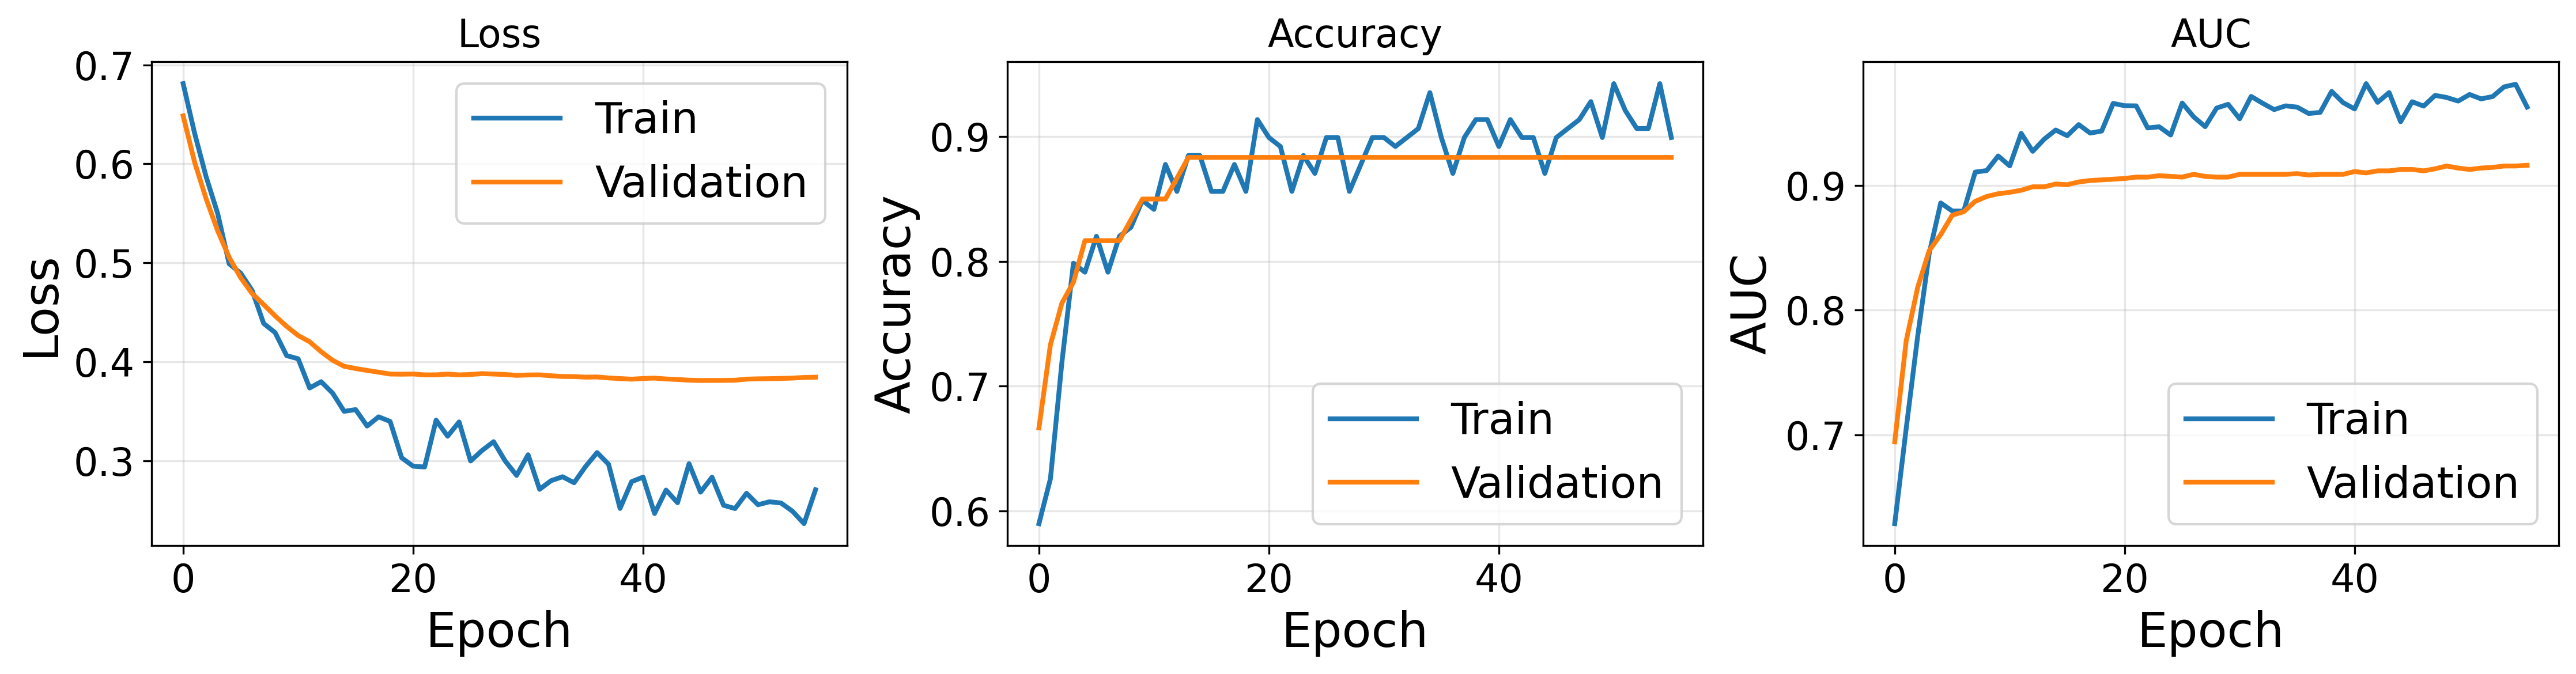

In [5]:
# Training curves of the original run (head training + fine-tuning)
display(IPImage(filename=f"{root}/training_curves_0408.png", width=900))

## 3. Evaluation on the representative slice (one image per test patient)

In [6]:
test_df["y_prob"] = model.predict(test_img, batch_size=32, verbose=0).ravel()
test_df.to_csv(f"{out_dir}/single_image_test_pred.csv", index=False)

# Same value as in the original run (all 60 test patients)
print("AUC, all 60 test patients:", round(roc_auc_score(test_df["label"], test_df["y_prob"]), 4))

AUC, all 60 test patients: 0.9133


## 4. All gallbladder slices of each test patient (hybrid masks)

Gallbladder masks were obtained with TotalSegmentator.
- **Original masks** (`seg_out`): TotalSegmentator with `--roi_subset`.
- **Re-segmented masks** (`seg_out_full_noroi`): TotalSegmentator without `--roi_subset` and without `--fast` (all structures, full resolution).

**Hybrid policy**: the original masks are used by default; only for patients in whom the original mask contained no gallbladder
slice, the re-segmented masks are used. Every slice containing the mask is cropped with the bounding box of the mask plus a
15-pixel margin, and the same artefact removal as for the training images is applied (thin peripheral lines and blown-out white regions).

In [7]:
# ===== Preprocessing: removal of thin peripheral lines and blown-out white regions =====
import os
import re
import glob
import cv2
import numpy as np
import pandas as pd


def fill_mask_by_component_ring_median(img_rgb, mask, ring_ksize=21):
    """
    Fill each connected component of the mask with the median colour of the ring around it
    """
    out = img_rgb.copy()
    region_all = (mask > 0).astype(np.uint8)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(region_all, connectivity=8)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ring_ksize, ring_ksize))

    for i in range(1, num_labels):
        region = (labels == i).astype(np.uint8)
        if region.sum() == 0:
            continue

        dil = cv2.dilate(region, kernel, iterations=1)
        ring = (dil == 1) & (region == 0) & (region_all == 0)

        if np.any(ring):
            color = np.median(out[ring], axis=0).astype(np.uint8)
            out[region.astype(bool)] = color

    return out


def detect_outer_thin_artifacts_on_dark_bg(
    img_rgb,
    border_width=80,
    bg_thr=60,
    canny1=20,
    canny2=80,
    min_area=10,
    min_length=20,
    max_thickness=20,
    min_aspect=1.5,
    close_ksize=7,
    dilate_iter=2,
):
    h, w = img_rgb.shape[:2]
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

    # Peripheral ROI
    border_mask = np.zeros((h, w), np.uint8)
    border_mask[:border_width, :] = 255
    border_mask[-border_width:, :] = 255
    border_mask[:, :border_width] = 255
    border_mask[:, -border_width:] = 255

    # Dark background mask
    dark_bg = (gray <= bg_thr).astype(np.uint8) * 255

    # Edges
    edges = cv2.Canny(gray, canny1, canny2)

    # Thicken the lines
    kernel_d = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    edges = cv2.dilate(edges, kernel_d, iterations=dilate_iter)

    # Periphery only
    cand = cv2.bitwise_and(edges, border_mask)

    # On the dark background only
    cand = cv2.bitwise_and(cand, dark_bg)

    # Connect broken segments
    kernel_c = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_ksize, close_ksize))
    cand = cv2.morphologyEx(cand, cv2.MORPH_CLOSE, kernel_c)

    # Select components
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(cand, connectivity=8)
    mask = np.zeros_like(cand)

    for i in range(1, num_labels):
        x, y, ww, hh, area = stats[i]

        if area < min_area:
            continue

        long_side = max(ww, hh)
        short_side = max(1, min(ww, hh))
        aspect = long_side / short_side

        if long_side < min_length:
            continue
        if short_side > max_thickness:
            continue
        if aspect < min_aspect:
            continue

        mask[labels == i] = 255

    return mask

def suppress_blowout_after_line_removal(
    img_rgb,
    white_thr=210,
    sat_thr=70,
    min_area=10,
    close_ksize=7,
    dilate_iter=2,
    ring_ksize=21,
):
    """
    After line removal, detect and fill blown-out (overexposed) white regions
    """
    img = img_rgb.copy()

    gray_mask = (img.mean(axis=2) >= white_thr)

    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    _, s, v = cv2.split(hsv)
    hsv_mask = (v >= white_thr) & (s <= sat_thr)

    mask = (gray_mask | hsv_mask).astype(np.uint8) * 255

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    clean_mask = np.zeros_like(mask)

    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean_mask[labels == i] = 255

    kernel_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_ksize, close_ksize))
    clean_mask = cv2.morphologyEx(clean_mask, cv2.MORPH_CLOSE, kernel_close)

    kernel_dil = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    clean_mask = cv2.dilate(clean_mask, kernel_dil, iterations=dilate_iter)

    out = fill_mask_by_component_ring_median(img, clean_mask, ring_ksize=ring_ksize)
    return out, clean_mask


def preprocess_remove_outer_lines_then_blowout(
    img_rgb,

    # outer line artifact params
    border_width=80,
    bg_thr=40,
    canny1=30,
    canny2=100,
    line_min_area=10,
    line_min_length=20,
    line_max_thickness=10,
    line_min_aspect=2.0,
    line_close_ksize=3,
    line_dilate_iter=1,
    line_ring_ksize=21,

    # white blowout params
    white_thr=210,
    sat_thr=70,
    white_min_area=10,
    white_close_ksize=7,
    white_dilate_iter=2,
    white_ring_ksize=21,
):
    """
    1) Remove thin lines on the dark background at the periphery
    2) Remove the remaining blown-out white regions
    """
    # 1) Detect peripheral lines
    line_mask = detect_outer_thin_artifacts_on_dark_bg(
        img_rgb,
        border_width=border_width,
        bg_thr=bg_thr,
        canny1=canny1,
        canny2=canny2,
        min_area=line_min_area,
        min_length=line_min_length,
        max_thickness=line_max_thickness,
        min_aspect=line_min_aspect,
        close_ksize=line_close_ksize,
        dilate_iter=line_dilate_iter,
    )

    # 2) Remove the lines
    img_no_line = fill_mask_by_component_ring_median(
        img_rgb,
        line_mask,
        ring_ksize=line_ring_ksize,
    )

    # 3) Remove blown-out white regions
    img_final, white_mask = suppress_blowout_after_line_removal(
        img_no_line,
        white_thr=white_thr,
        sat_thr=sat_thr,
        min_area=white_min_area,
        close_ksize=white_close_ksize,
        dilate_iter=white_dilate_iter,
        ring_ksize=white_ring_ksize,
    )

    return img_final, line_mask, white_mask

In [8]:
# ===== Crop all slices containing the gallbladder mask =====
def crop_all_slices_for_patient(group, case_no, margin=15, out_root=None, seg_root=None):
    """
    For one patient, crop every z-slice in which the gallbladder mask exists
    (bounding box + margin), apply the peripheral-line / blown-out-white removal, and save it.

    This extends the single-slice crop of the representative image
    to all z-slices that contain the mask.
    preprocess_remove_outer_lines_then_blowout is defined in the preprocessing cell above.

    seg_root: root directory of the masks (gallbladder.nii.gz).
              Defaults to f"{root}/seg_out" (original masks, TotalSegmentator with --roi_subset).
              Pass f"{root}/seg_out_full_noroi" (re-segmented without --roi_subset and without --fast)
              to use the re-segmented masks instead.
    """
    if seg_root is None:
        seg_root = f"{root}/seg_out"

    seg_path = f"{seg_root}/{group}/{case_no}/gallbladder.nii.gz"
    png_dir = f"{root}/RGB/{group}/{case_no}"

    if not os.path.exists(seg_path) or not os.path.isdir(png_dir):
        print(f"skip {group}/{case_no}: missing seg or png dir")
        return []

    seg = nib.load(seg_path).get_fdata()
    if np.count_nonzero(seg) == 0:
        print(f"skip {group}/{case_no}: empty mask")
        return []

    png_files = sorted([
        f for f in os.listdir(png_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    # Use only z-slices that contain the mask
    zs = np.where(seg.sum(axis=(0, 1)) > 0)[0]

    saved = []
    for z in zs:
        z = int(z)
        if z >= len(png_files):
            continue

        mask_slice = seg[:, :, z] > 0
        mask_for_display = mask_slice.T
        mask_for_whole = np.flipud(mask_for_display)

        png_path = os.path.join(png_dir, png_files[z])
        img = np.array(Image.open(png_path))
        if img.ndim == 2:
            img_rgb = np.stack([img, img, img], axis=-1).astype(np.uint8)
        else:
            img_rgb = img[..., :3].astype(np.uint8)

        if mask_for_whole.shape != img_rgb.shape[:2]:
            print(f"  skip z={z}: shape mismatch")
            continue

        ys, xs = np.where(mask_for_whole)
        if len(xs) == 0:
            continue

        h, w = mask_for_whole.shape
        x0, x1 = xs.min(), xs.max()
        y0, y1 = ys.min(), ys.max()
        cx0 = max(0, x0 - margin)
        cx1 = min(w - 1, x1 + margin)
        cy0 = max(0, y0 - margin)
        cy1 = min(h - 1, y1 + margin)

        crop_rgb = img_rgb[cy0:cy1 + 1, cx0:cx1 + 1]

        fixed_rgb, _, _ = preprocess_remove_outer_lines_then_blowout(
            crop_rgb,
            border_width=100, bg_thr=50, canny1=20, canny2=80,
            line_min_area=8, line_min_length=15, line_max_thickness=12,
            line_min_aspect=1.8, line_close_ksize=3, line_dilate_iter=1, line_ring_ksize=21,
            white_thr=210, sat_thr=70, white_min_area=5,
            white_close_ksize=7, white_dilate_iter=2, white_ring_ksize=21,
        )

        save_dir = os.path.join(out_root, group, str(case_no))
        os.makedirs(save_dir, exist_ok=True)
        filename = f"ct_crop_z{z:03d}.png"
        save_path = os.path.join(save_dir, filename)
        Image.fromarray(fixed_rgb).save(save_path)
        saved.append({"path": save_path, "z": z})

    return saved

In [9]:
seg_root_old = f"{root}/seg_out"
seg_root_new = f"{root}/seg_out_full_noroi"
crop_root_old = f"{root}/cropped_slices_RGB_outerline_white_fixed_margin_15_all_slices"
crop_root_new = f"{root}/cropped_slices_RGB_outerline_white_fixed_margin_15_all_slices_full_noroi"
index_old = f"{root}/img_path_all_slices_test_20260701.csv"
index_new = f"{root}/img_path_all_slices_test_20260702_full_noroi.csv"

def crop_test_patients(seg_root, out_root):
    records = []
    for _, row in test_df.iterrows():
        group = "normal" if row["label"] == 0 else "cholecystitis"
        case_no = str(int(row["local_patient_id"]))
        for s in crop_all_slices_for_patient(group, case_no, margin=15, out_root=out_root, seg_root=seg_root):
            records.append({"path": s["path"], "z": s["z"], "group": group, "patient_id": row["patient_id"],
                            "local_patient_id": row["local_patient_id"], "label": row["label"]})
    return pd.DataFrame(records)

if RUN_CROPPING:
    slices_old = crop_test_patients(seg_root_old, crop_root_old)
    slices_new = crop_test_patients(seg_root_new, crop_root_new)
    slices_old.to_csv(index_old, index=False)
    slices_new.to_csv(index_new, index=False)
else:
    slices_old = pd.read_csv(index_old)
    slices_new = pd.read_csv(index_new)

print("original masks    :", len(slices_old), "slices /", slices_old["patient_id"].nunique(), "patients")
print("re-segmented masks:", len(slices_new), "slices /", slices_new["patient_id"].nunique(), "patients")

original masks    : 490 slices / 55 patients
re-segmented masks: 504 slices / 58 patients


## 5. Slice-level prediction and the hybrid set

In [10]:
slices_old["y_prob"] = model.predict(load_images(slices_old["path"].tolist()), batch_size=32, verbose=0).ravel()
slices_new["y_prob"] = model.predict(load_images(slices_new["path"].tolist()), batch_size=32, verbose=0).ravel()

# Reproducibility check against the slice-level predictions saved in the original run
for name, df_now, saved in [
    ("original masks", slices_old, f"{root}/img_path_all_slices_test_20260701_with_pred.csv"),
    ("re-segmented masks", slices_new, f"{root}/img_path_all_slices_test_20260702_full_noroi_with_pred.csv"),
]:
    ref = pd.read_csv(saved)
    diff = np.abs(df_now.merge(ref[["path", "y_prob"]], on="path", suffixes=("", "_saved"))
                  .eval("y_prob - y_prob_saved")).max()
    print(f"{name}: max |difference| from the saved predictions = {diff:.2e}")

original masks: max |difference| from the saved predictions = 2.98e-08
re-segmented masks: max |difference| from the saved predictions = 2.97e-08


In [11]:
# Hybrid: original masks by default; re-segmented masks only for patients with no slice in the original masks
fallback_patients = sorted(set(slices_new["patient_id"]) - set(slices_old["patient_id"]))
slices_hybrid = pd.concat(
    [slices_old.assign(mask_source="original"),
     slices_new[slices_new["patient_id"].isin(fallback_patients)].assign(mask_source="re-segmented")],
    ignore_index=True,
)
slices_hybrid.to_csv(f"{out_dir}/all_slices_hybrid_test_pred.csv", index=False)

no_slice = sorted(set(test_df["patient_id"]) - set(slices_hybrid["patient_id"]))
print("patients taken from the re-segmented masks:", fallback_patients)
print("test patients without any gallbladder slice in either mask:", no_slice)
print("hybrid:", len(slices_hybrid), "slices /", slices_hybrid["patient_id"].nunique(), "patients")

patients taken from the re-segmented masks: [7, 20, 100, 177]
test patients without any gallbladder slice in either mask: [87]
hybrid: 527 slices / 59 patients


## 6. Patient-level evaluation with 95% confidence intervals

- **Patient-level rule**: a patient is classified as positive if any slice has a predicted probability ≥ 0.5;
  the maximum slice-level probability is used as the patient-level score for the ROC curve.
- **Confidence intervals**: accuracy, sensitivity, specificity, PPV and NPV use the Wilson score interval;
  AUC and F1 use a stratified bootstrap (patients resampled with replacement within the positive and negative groups,
  2,000 resamples, percentile method).
- Controls No. 87 and 97 are excluded (`EXCLUDE_PATIENT_IDS`).

In [12]:
# ===== Functions for metrics and 95% confidence intervals =====
N_BOOT = 2000
SEED = 42

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def bootstrap_ci(y_true, y_prob, stat_fn, n_boot=N_BOOT, seed=SEED):
    # Resample within each class so that every bootstrap sample contains both positives and negatives
    rng = np.random.default_rng(seed)
    pos = np.where(y_true == 1)[0]
    neg = np.where(y_true == 0)[0]
    vals = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos), replace=True), rng.choice(neg, len(neg), replace=True)])
        vals.append(stat_fn(y_true[idx], y_prob[idx]))
    return np.percentile(vals, 2.5), np.percentile(vals, 97.5)

def compute_metrics(y_true, y_prob, threshold=THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    f1_fn = lambda yt, yp: f1_score(yt, (yp >= threshold).astype(int), zero_division=0)
    rows = [
        ("AUC", roc_auc_score(y_true, y_prob), *bootstrap_ci(y_true, y_prob, roc_auc_score)),
        ("Accuracy", (tp + tn) / len(y_true), *wilson_ci(tp + tn, len(y_true))),
        ("Sensitivity (recall)", tp / (tp + fn), *wilson_ci(tp, tp + fn)),
        ("Specificity", tn / (tn + fp), *wilson_ci(tn, tn + fp)),
        ("PPV (precision)", tp / (tp + fp) if tp + fp > 0 else np.nan, *wilson_ci(tp, tp + fp)),
        ("NPV", tn / (tn + fn) if tn + fn > 0 else np.nan, *wilson_ci(tn, tn + fn)),
        ("F1 score", f1_fn(y_true, y_prob), *bootstrap_ci(y_true, y_prob, f1_fn)),
    ]
    df = pd.DataFrame(rows, columns=["metric", "value", "ci_low", "ci_high"])
    df["value (95% CI)"] = df.apply(lambda r: f"{r['value']:.3f} ({r['ci_low']:.3f}–{r['ci_high']:.3f})", axis=1)
    counts = {"n": len(y_true), "TN": tn, "FP": fp, "FN": fn, "TP": tp}
    return df, counts

In [13]:
# ===== Patient-level scores =====
patient_hybrid = (
    slices_hybrid.assign(is_positive=(slices_hybrid["y_prob"] >= THRESHOLD))
    .groupby("patient_id")
    .agg(label=("label", "first"), mask_source=("mask_source", "first"), n_slices=("y_prob", "size"),
         max_prob=("y_prob", "max"), positive_rate=("is_positive", "mean"))
    .reset_index()
)
patient_hybrid = patient_hybrid[~patient_hybrid["patient_id"].isin(EXCLUDE_PATIENT_IDS)].reset_index(drop=True)
single = test_df[~test_df["patient_id"].isin(EXCLUDE_PATIENT_IDS)].reset_index(drop=True)
patient_hybrid.to_csv(f"{out_dir}/all_slices_hybrid_patient_level.csv", index=False)

print("all-slice evaluation:", len(patient_hybrid), "patients", patient_hybrid["label"].value_counts().to_dict())
print("representative-slice evaluation:", len(single), "patients", single["label"].value_counts().to_dict())

all-slice evaluation: 58 patients {1: 30, 0: 28}
representative-slice evaluation: 58 patients {1: 30, 0: 28}


In [14]:
# ===== Metrics with 95% confidence intervals =====
evaluations = [
    ("All slices, any slice positive (main result)", patient_hybrid, "max_prob"),
    ("All slices, majority vote (reference)", patient_hybrid, "positive_rate"),
    ("Representative slice (reference)", single, "y_prob"),
]

results, count_rows = [], []
for name, d, score_col in evaluations:
    m, counts = compute_metrics(d["label"].values, d[score_col].values)
    results.append(m.assign(evaluation=name))
    count_rows.append({"evaluation": name, **counts})

df_results = pd.concat(results, ignore_index=True)
df_counts = pd.DataFrame(count_rows)
df_results.merge(df_counts, on="evaluation").to_csv(f"{out_dir}/metrics_95ci.csv", index=False)

pd.set_option("display.max_colwidth", None)
display(df_counts)
display(df_results.pivot(index="evaluation", columns="metric", values="value (95% CI)")
        .loc[[e[0] for e in evaluations],
             ["AUC", "Accuracy", "Sensitivity (recall)", "Specificity", "PPV (precision)", "NPV", "F1 score"]])

,evaluation,n,TN,FP,FN,TP
0,"All slices, any slice positive (main result)",58,17,11,4,26
1,"All slices, majority vote (reference)",58,25,3,7,23
2,Representative slice (reference),58,23,5,2,28


metric,AUC,Accuracy,Sensitivity (recall),Specificity,PPV (precision),NPV,F1 score
evaluation,,,,,,,
"All slices, any slice positive (main result)",0.868 (0.764–0.955),0.741 (0.616–0.837),0.867 (0.703–0.947),0.607 (0.424–0.764),0.703 (0.542–0.825),0.810 (0.600–0.923),0.776 (0.685–0.866)
"All slices, majority vote (reference)",0.832 (0.703–0.943),0.828 (0.711–0.904),0.767 (0.591–0.882),0.893 (0.728–0.963),0.885 (0.710–0.960),0.781 (0.612–0.890),0.821 (0.704–0.915)
Representative slice (reference),0.907 (0.811–0.983),0.879 (0.771–0.940),0.933 (0.787–0.982),0.821 (0.644–0.921),0.848 (0.691–0.933),0.920 (0.750–0.978),0.889 (0.812–0.952)


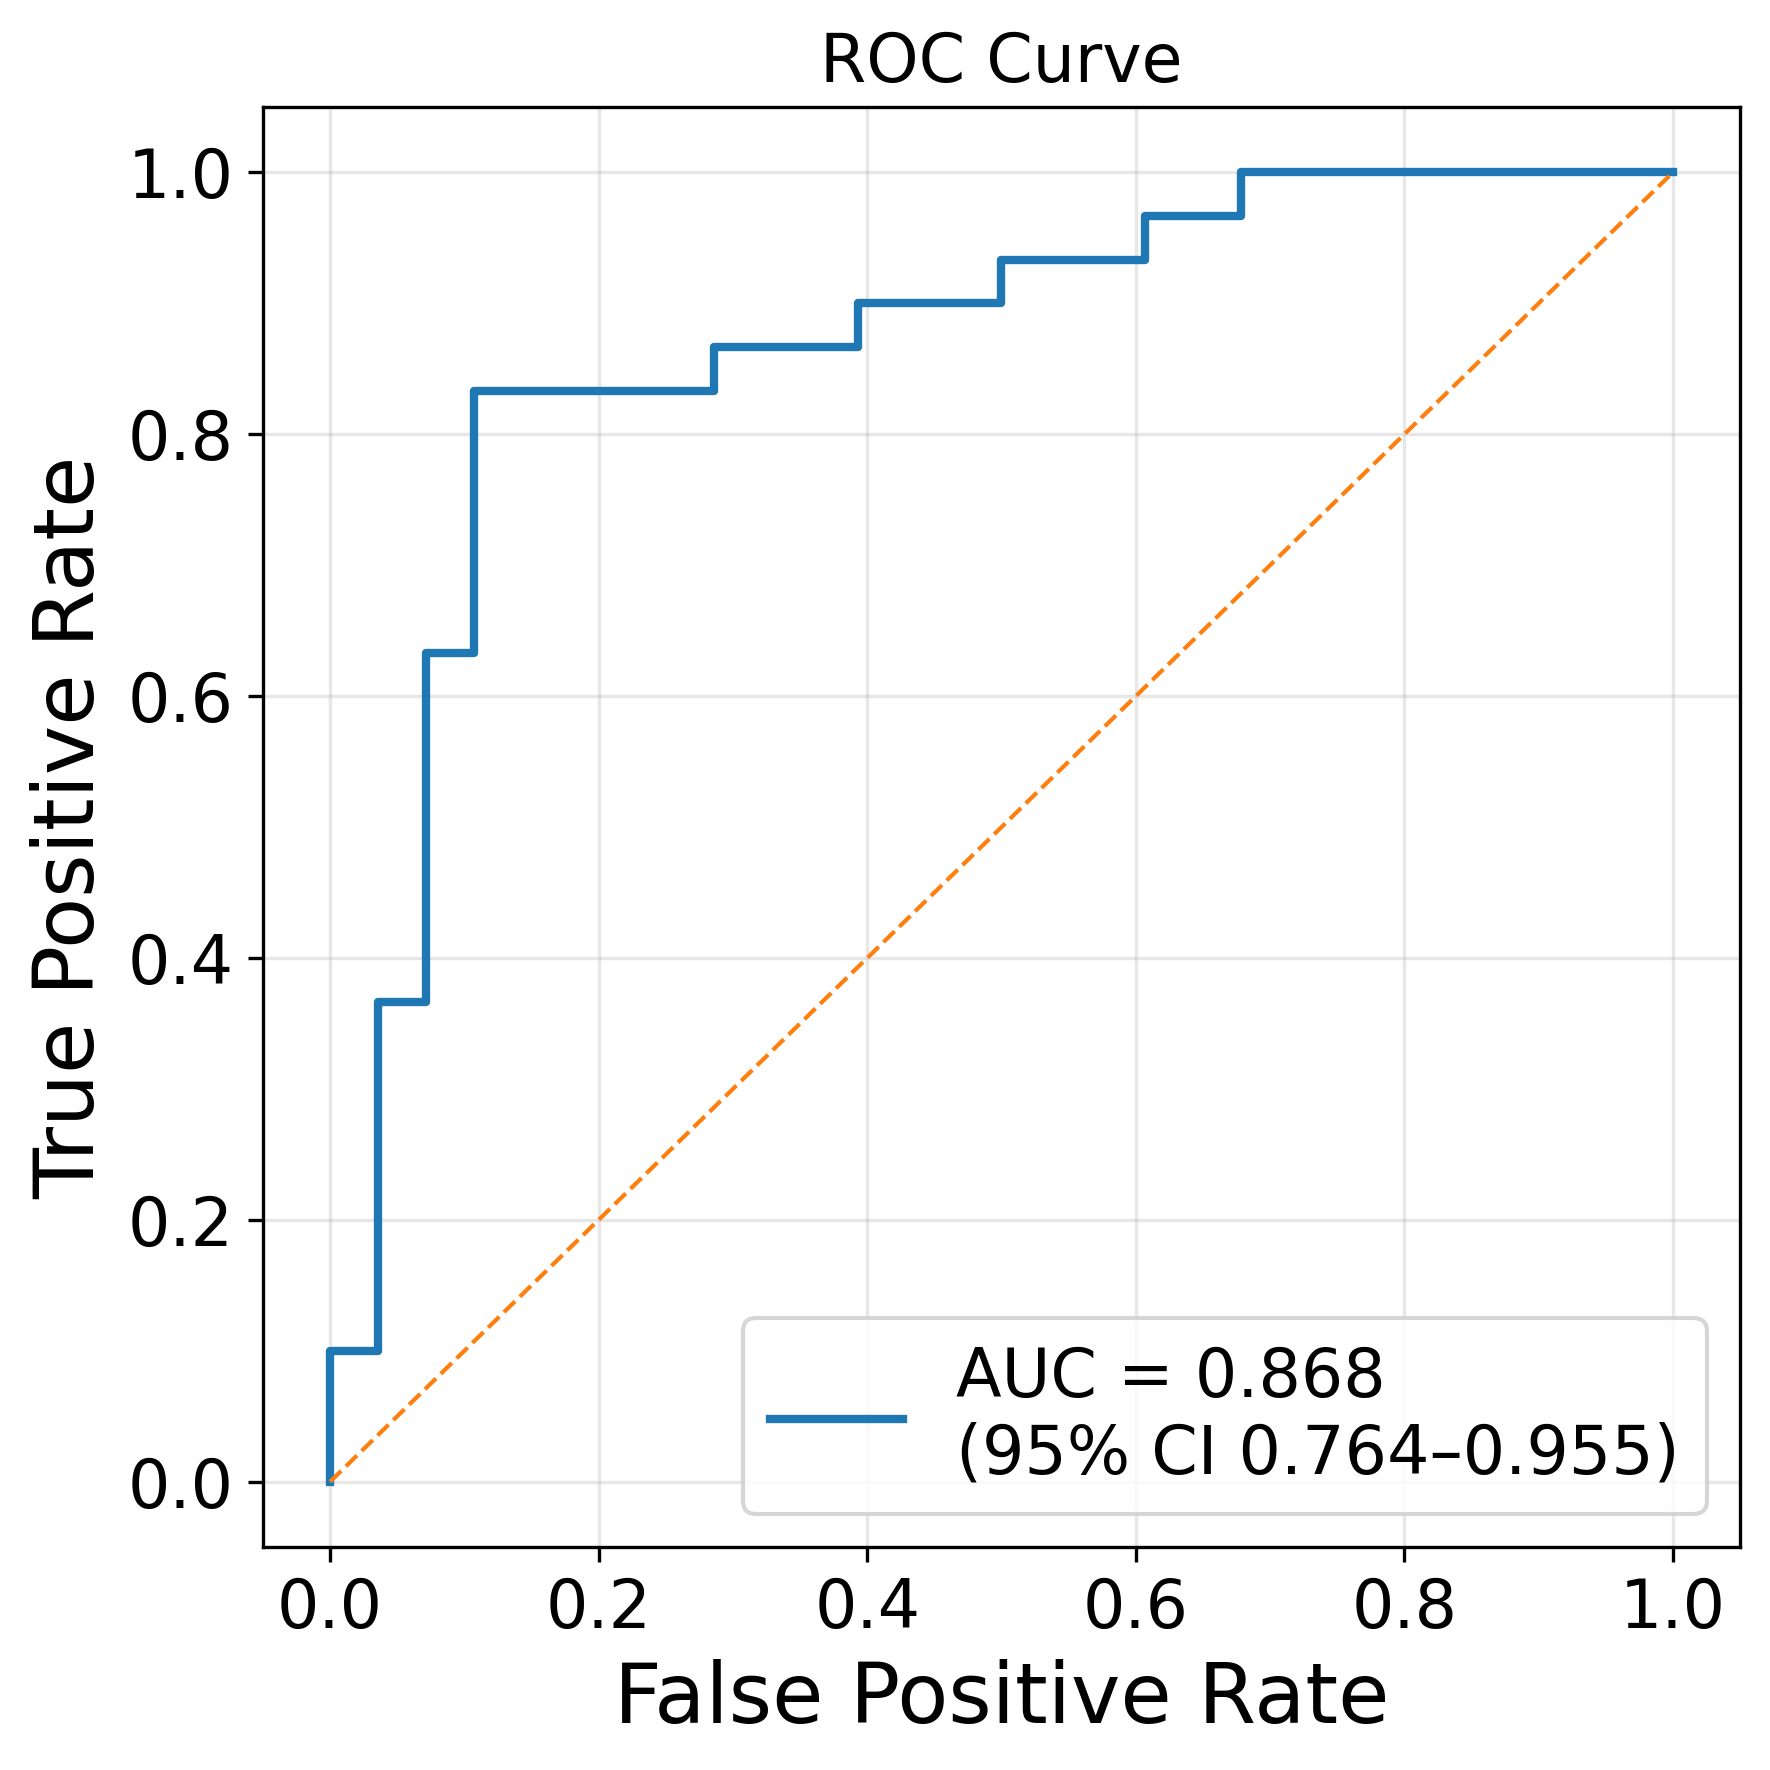

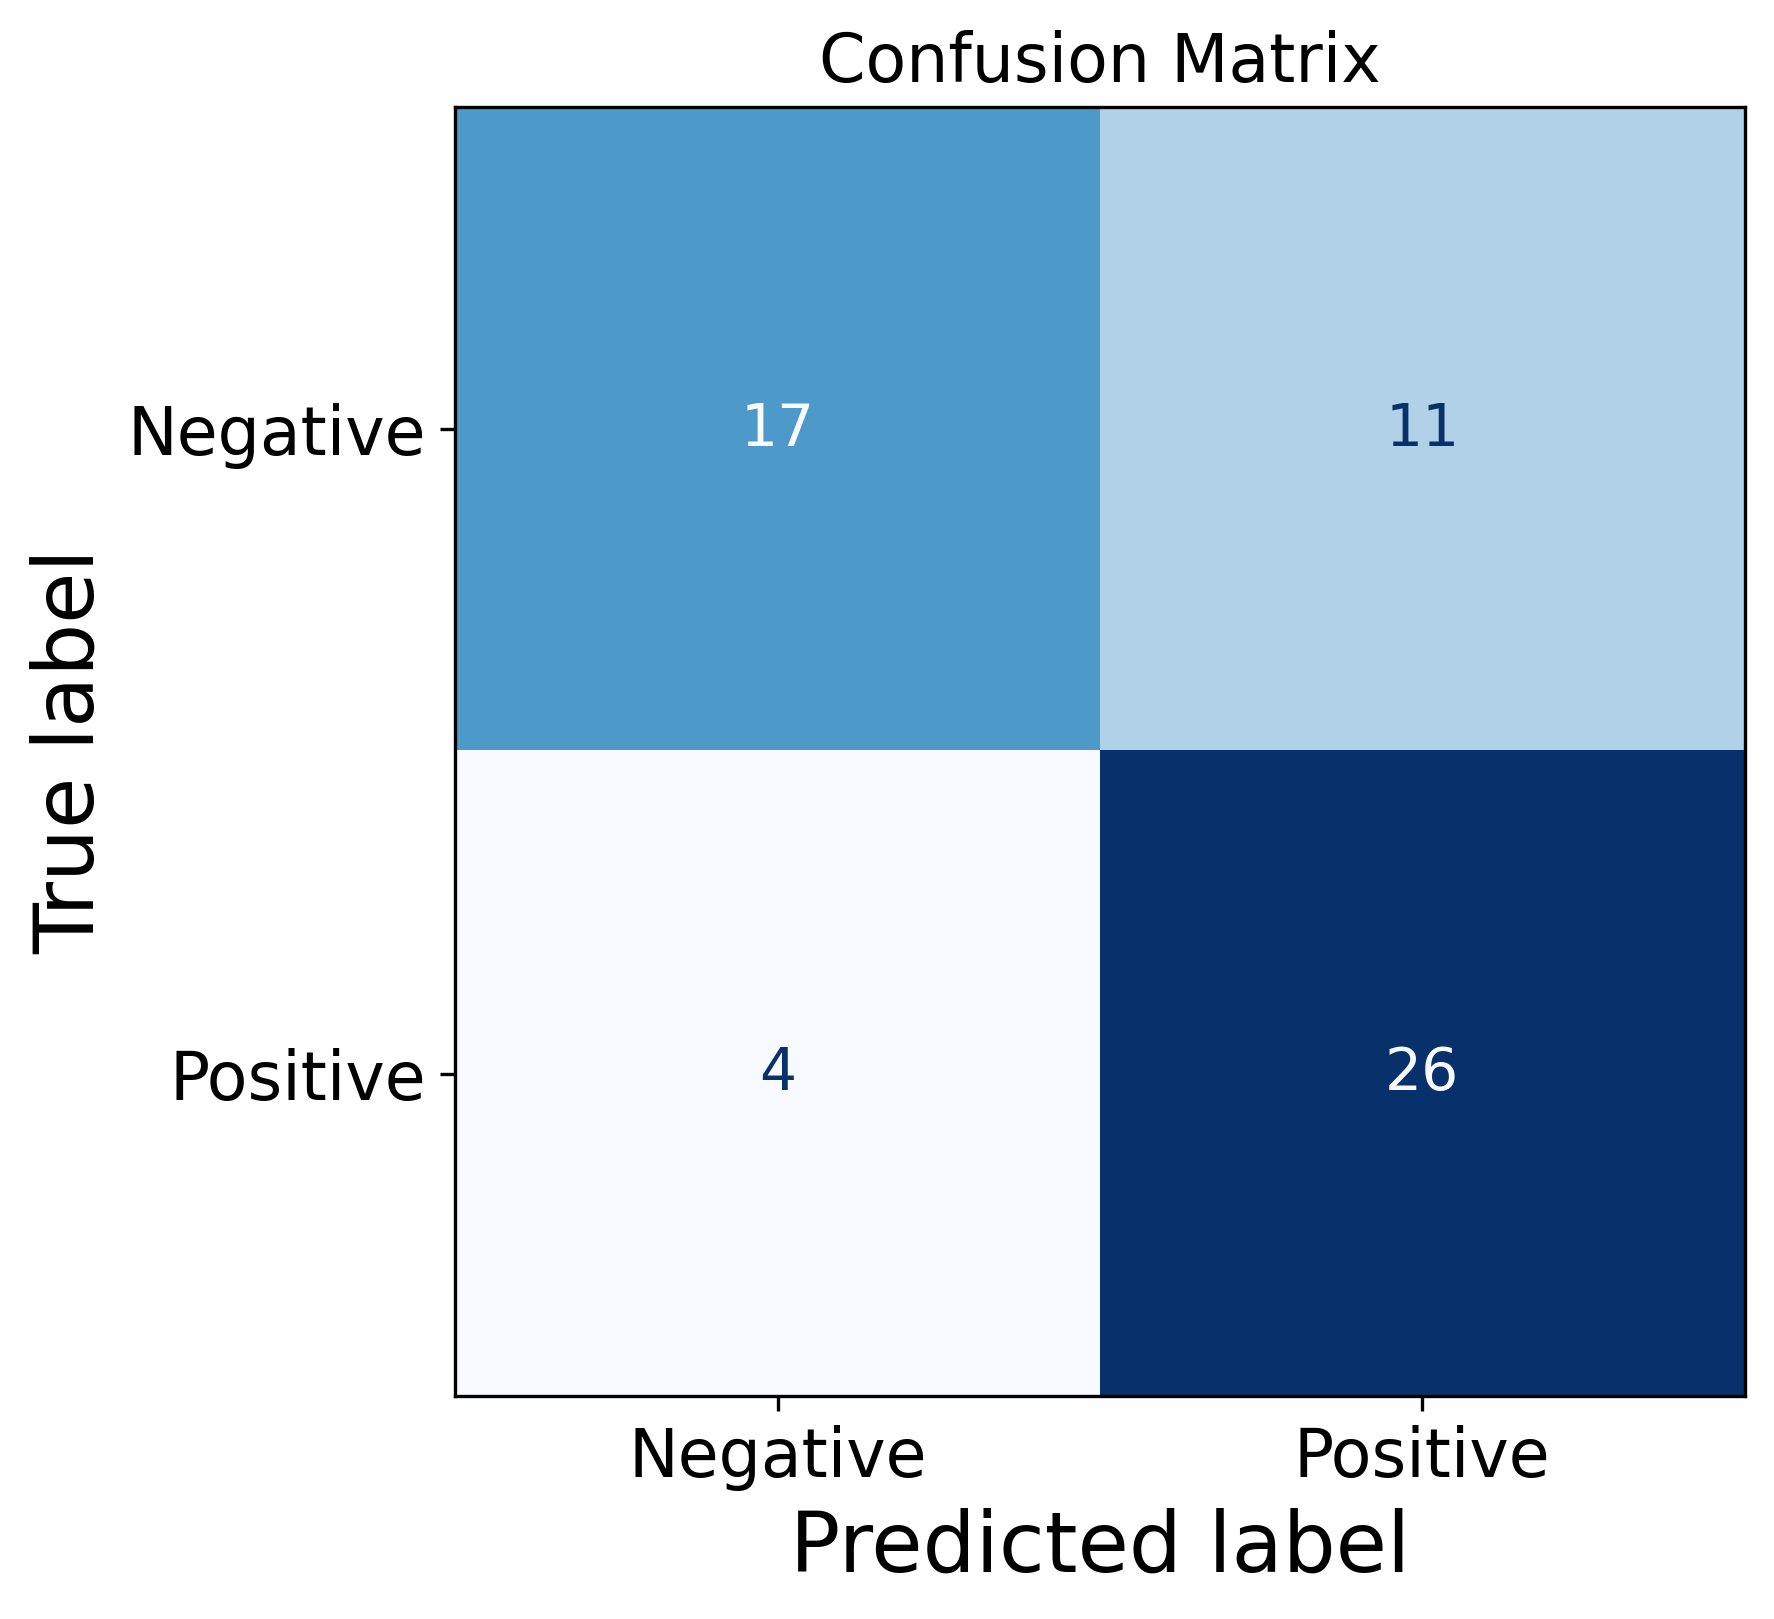

In [15]:
# ===== ROC curve and confusion matrix of the main result =====
main = df_results[df_results["evaluation"] == evaluations[0][0]].set_index("metric")
y_true_main = patient_hybrid["label"].values.astype(int)
y_score_main = patient_hybrid["max_prob"].values

fpr, tpr, _ = roc_curve(y_true_main, y_score_main)
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
ax.plot(fpr, tpr, linewidth=2,
        label=f"AUC = {main.loc['AUC', 'value']:.3f}\n(95% CI {main.loc['AUC', 'ci_low']:.3f}–{main.loc['AUC', 'ci_high']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
ax.set_xlabel("False Positive Rate", fontsize=20)
ax.set_ylabel("True Positive Rate", fontsize=20)
ax.set_title("ROC Curve", fontsize=16)
ax.tick_params(axis="both", labelsize=16)
ax.legend(fontsize=16, loc="lower right", frameon=True)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{out_dir}/roc_all_slices_hybrid_any_positive.png", dpi=300, bbox_inches="tight")
plt.show()

cm = confusion_matrix(y_true_main, (y_score_main >= THRESHOLD).astype(int), labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 6), dpi=300)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
ax.grid(False)
ax.set_title("Confusion Matrix", fontsize=16)
ax.set_xlabel("Predicted label", fontsize=20)
ax.set_ylabel("True label", fontsize=20)
ax.tick_params(axis="both", labelsize=16)
for text in disp.text_.ravel():
    text.set_fontsize(14)
plt.tight_layout()
plt.savefig(f"{out_dir}/confusion_matrix_all_slices_hybrid_any_positive.png", dpi=300, bbox_inches="tight")
plt.show()